
# FlightAura — NLP Preprocessing and Classical Machine Learning

## Objective

Prepare the airline passenger review dataset for NLP and machine learning experiments.

## Main tasks

1. Inspect and validate the actual dataset.
2. Investigate suspicious or inconsistent records.
3. Clean text and structured columns.
4. Create rating-derived sentiment labels.
5. Perform exploratory data analysis.
6. Experiment with NLTK preprocessing techniques.
7. Compare Bag of Words and TF-IDF representations.
8. Train Word2Vec embeddings.
9. Train and evaluate classical ML models.
10. Perform anomaly detection.

## Dataset

Airline Reviews Dataset — 8,100 records.

## Important

The original dataset must remain unchanged. All preprocessing will be performed on a separate working DataFrame.


In [4]:

# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

# Data manipulation
import pandas as pd
import numpy as np

# Text processing
import re
import html
import string

# File handling
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid")

print("Imports completed successfully.")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


Imports completed successfully.
Pandas: 2.3.3
NumPy: 1.26.4


In [5]:

# ==========================================
# 2. PROJECT PATH CONFIGURATION
# ==========================================

CURRENT_DIR = Path.cwd()

# Find the FlightAura project root
PROJECT_DIR = None

for candidate in [CURRENT_DIR, *CURRENT_DIR.parents]:

    if (candidate / "dataset" / "airlines_reviews.csv").exists():
        PROJECT_DIR = candidate
        break

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not locate FlightAura/dataset/airlines_reviews.csv. "
        "Check the notebook's location and dataset filename."
    )

DATASET_DIR = PROJECT_DIR / "dataset"
DATA_PATH = DATASET_DIR / "airlines_reviews.csv"

MODELS_DIR = PROJECT_DIR / "models"
CLASSICAL_DIR = MODELS_DIR / "classical"
EMBEDDINGS_DIR = MODELS_DIR / "embeddings"

CLASSICAL_DIR.mkdir(parents=True, exist_ok=True)
EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())
print("Classical model directory:", CLASSICAL_DIR)
print("Embedding directory:", EMBEDDINGS_DIR)


Project directory: c:\Users\HP\Documents\Projects\FlightAura
Dataset path: c:\Users\HP\Documents\Projects\FlightAura\dataset\airlines_reviews.csv
Dataset exists: True
Classical model directory: c:\Users\HP\Documents\Projects\FlightAura\models\classical
Embedding directory: c:\Users\HP\Documents\Projects\FlightAura\models\embeddings


In [7]:

# ==========================================
# 4. SCHEMA VALIDATION
# ==========================================

# Load original dataset
df = pd.read_csv(DATA_PATH, low_memory=False)

EXPECTED_COLUMNS = [
    "Title",
    "Name",
    "Review Date",
    "Airline",
    "Verified",
    "Reviews",
    "Type of Traveller",
    "Month Flown",
    "Route",
    "Class",
    "Seat Comfort",
    "Staff Service",
    "Food & Beverages",
    "Inflight Entertainment",
    "Value For Money",
    "Overall Rating",
    "Recommended"
]

missing_columns = [
    col for col in EXPECTED_COLUMNS
    if col not in df.columns
]

unexpected_columns = [
    col for col in df.columns
    if col not in EXPECTED_COLUMNS
]

print("Missing expected columns:", missing_columns)
print("Unexpected columns:", unexpected_columns)

assert len(missing_columns) == 0, "Dataset schema does not match!"

print("\nSchema validation successful.")


Missing expected columns: []
Unexpected columns: []

Schema validation successful.


In [8]:

# ==========================================
# 5. COLUMN DEFINITIONS
# ==========================================

TEXT_COLUMNS = [
    "Title",
    "Reviews"
]

IDENTIFIER_COLUMNS = [
    "Name"
]

CATEGORICAL_COLUMNS = [
    "Airline",
    "Verified",
    "Type of Traveller",
    "Route",
    "Class",
    "Recommended"
]

RATING_COLUMNS = [
    "Seat Comfort",
    "Staff Service",
    "Food & Beverages",
    "Inflight Entertainment",
    "Value For Money"
]

TARGET_COLUMNS = [
    "Overall Rating",
    "Recommended"
]

DATE_COLUMNS = [
    "Review Date",
    "Month Flown"
]

print("Text columns:", TEXT_COLUMNS)
print("Identifier columns:", IDENTIFIER_COLUMNS)
print("Categorical columns:", CATEGORICAL_COLUMNS)
print("Rating columns:", RATING_COLUMNS)
print("Target columns:", TARGET_COLUMNS)
print("Date columns:", DATE_COLUMNS)


Text columns: ['Title', 'Reviews']
Identifier columns: ['Name']
Categorical columns: ['Airline', 'Verified', 'Type of Traveller', 'Route', 'Class', 'Recommended']
Rating columns: ['Seat Comfort', 'Staff Service', 'Food & Beverages', 'Inflight Entertainment', 'Value For Money']
Target columns: ['Overall Rating', 'Recommended']
Date columns: ['Review Date', 'Month Flown']


In [9]:

# ==========================================
# 6. TEXT WHITESPACE INSPECTION
# ==========================================

whitespace_results = []

for col in TEXT_COLUMNS + ["Name"]:

    original = df[col].astype("string")

    trimmed = original.str.strip()

    affected = original.notna() & original.ne(trimmed)

    whitespace_results.append({
        "Column": col,
        "Total Values": original.notna().sum(),
        "Whitespace Affected": affected.sum(),
        "Percentage Affected": round(
            affected.sum() / max(original.notna().sum(), 1) * 100,
            2
        )
    })

    print("\nCOLUMN:", col)

    if affected.any():

        print("Examples before trimming:")

        display(
            pd.DataFrame({
                "Original": original[affected].head(5),
                "After strip": trimmed[affected].head(5)
            })
        )

display(pd.DataFrame(whitespace_results))



COLUMN: Title
Examples before trimming:


,Original,After strip
1,seats on this aircraft are dreadful,seats on this aircraft are dreadful
9,can’t fault a single aspect,can’t fault a single aspect
20,Barely any room to move,Barely any room to move
22,brilliant experience,brilliant experience
23,best alongside Qatar Airways,best alongside Qatar Airways



COLUMN: Reviews
Examples before trimming:


,Original,After strip
0,"Flight was amazing. The crew onboard this flight were very welcoming, and gave a good atmosphere. The crew serving...","Flight was amazing. The crew onboard this flight were very welcoming, and gave a good atmosphere. The crew serving m..."
1,Booking an emergency exit seat still meant huge discomfort in a seat far too narrow and poor padding meaning back ...,Booking an emergency exit seat still meant huge discomfort in a seat far too narrow and poor padding meaning back ac...
2,Excellent performance on all fronts. I would definitely choose to use this airline again. The aircraft is well-mai...,Excellent performance on all fronts. I would definitely choose to use this airline again. The aircraft is well-maint...
3,Pretty comfortable flight considering I was flying in economy class in one of the older aircraft in their fleet whi...,Pretty comfortable flight considering I was flying in economy class in one of the older aircraft in their fleet whic...
4,The service was consistently good from start to finish. The cabin crew showcased the friendly Singaporean culture a...,The service was consistently good from start to finish. The cabin crew showcased the friendly Singaporean culture at...



COLUMN: Name
Examples before trimming:


,Original,After strip
4,A Othman,A Othman
109,Eric Huang,Eric Huang
116,Cesare Recalcati,Cesare Recalcati
366,Stephen Mason,Stephen Mason
717,Kah Kay Au,Kah Kay Au


,Column,Total Values,Whitespace Affected,Percentage Affected
0,Title,8100,237,2.93
1,Reviews,8100,8100,100.00
2,Name,8100,78,0.96


In [10]:

# ==========================================
# 7. VERIFIED COLUMN INVESTIGATION
# ==========================================

verified_normalized = (
    df["Verified"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("All distinct values in Verified:")

display(
    verified_normalized.value_counts(dropna=False)
)

# Valid Boolean representations
valid_verified = ["true", "false"]

invalid_verified_mask = ~verified_normalized.isin(valid_verified)

print("\nNumber of irregular Verified entries:",
      invalid_verified_mask.sum())

print("\nIrregular records:")

display(
    df.loc[
        invalid_verified_mask,
        ["Airline", "Title", "Verified"]
    ]
)


All distinct values in Verified:


Verified
true                                                                                                                                                                                                                                           6216
false                                                                                                                                                                                                                                          1881
*unverified*                                                                                                                                                                                                                                      1
notverified                                                                                                                                                                                                                                       1
we do appreciat


Number of irregular Verified entries: 3

Irregular records:


,Airline,Title,Verified
2225,Qatar Airways,CSD was professional but friendly,*Unverified*
3358,Emirates,Very disappointed,NotVerified
3822,Emirates,they allocated us to different seats,we do appreciate you bringing this matter to our attention. Please accept my apologies for not having met your expec...


In [11]:

# ==========================================
# 8. INVESTIGATE ENTERTAINMENT RATING
# ==========================================

zero_entertainment = df[
    df["Inflight Entertainment"] == 0
]

print("Records with entertainment rating zero:",
      len(zero_entertainment))

display(
    zero_entertainment[
        [
            "Airline",
            "Title",
            "Reviews",
            "Seat Comfort",
            "Staff Service",
            "Food & Beverages",
            "Inflight Entertainment",
            "Value For Money",
            "Overall Rating",
            "Recommended"
        ]
    ]
)


Records with entertainment rating zero: 1


,Airline,Title,Reviews,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,Recommended
6757,Air France,no one is capable of giving you an answer,"After a long time and being French, I decided to give a chance to Air France. Unfortunately, this has been a disas...",1,1,5,0,1,1,no


In [12]:

# ==========================================
# 9. DUPLICATE REVIEW INVESTIGATION
# ==========================================

# Temporary normalized text for comparison only
normalized_reviews = (
    df["Reviews"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

duplicate_review_mask = normalized_reviews.duplicated(
    keep=False
)

duplicate_reviews = df.loc[
    duplicate_review_mask,
    [
        "Title",
        "Airline",
        "Reviews",
        "Overall Rating",
        "Recommended",
        "Staff Service",
        "Seat Comfort"
    ]
].copy()

print("Number of records belonging to duplicated review groups:",
      len(duplicate_reviews))

print("\nDuplicate review records:")

display(duplicate_reviews)

print("\nNumber of unique duplicated review texts:",
      normalized_reviews[duplicate_review_mask].nunique())


Number of records belonging to duplicated review groups: 4

Duplicate review records:


,Title,Airline,Reviews,Overall Rating,Recommended,Staff Service,Seat Comfort
3820,Hello Tomorrow? More like Hello Never,Emirates,"Unforgettable experience flying with Emirates from Singapore to Rome via Dubai. I was booked on flight EK433, with ...",2,no,5,3
3821,More like Hello Never,Emirates,"Unforgettable experience flying with Emirates from Singapore to Rome via Dubai. I was booked on flight EK433, with ...",2,no,2,5
7633,“an exceptional high level of service”,EVA Air,Another great set of flights R/T Bangkok to San Francisco via Taipei. The EVA service from start to finish was 5 S...,10,yes,5,5
7641,service from start to finish was 5 Star,EVA Air,Another great set of flights R/T Bangkok to San Francisco via Taipei. The EVA service from start to finish was 5 St...,10,yes,5,1



Number of unique duplicated review texts: 2


In [13]:

# ==========================================
# 10. DATE VALIDATION
# ==========================================

# Review Date format: YYYY-MM-DD
parsed_review_dates = pd.to_datetime(
    df["Review Date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Month Flown format: Month YYYY
parsed_flight_months = pd.to_datetime(
    df["Month Flown"],
    format="%B %Y",
    errors="coerce"
)

print("REVIEW DATE")
print("Valid dates:", parsed_review_dates.notna().sum())
print("Invalid dates:", parsed_review_dates.isna().sum())
print("Earliest date:", parsed_review_dates.min())
print("Latest date:", parsed_review_dates.max())

print("\nMONTH FLOWN")
print("Valid months:", parsed_flight_months.notna().sum())
print("Invalid months:", parsed_flight_months.isna().sum())
print("Earliest month:", parsed_flight_months.min())
print("Latest month:", parsed_flight_months.max())


REVIEW DATE
Valid dates: 8100
Invalid dates: 0
Earliest date: 2016-03-22 00:00:00
Latest date: 2024-03-06 00:00:00

MONTH FLOWN
Valid months: 8100
Invalid months: 0
Earliest month: 2013-03-01 00:00:00
Latest month: 2024-03-01 00:00:00


In [14]:

# ==========================================
# 11. RATING VALIDATION
# ==========================================

rating_ranges = {
    "Seat Comfort": (1, 5),
    "Staff Service": (1, 5),
    "Food & Beverages": (1, 5),
    "Inflight Entertainment": (0, 5),
    "Value For Money": (1, 5),
    "Overall Rating": (1, 10)
}

rating_validation = []

for col, (minimum, maximum) in rating_ranges.items():

    invalid_mask = (
        (df[col] < minimum) |
        (df[col] > maximum) |
        df[col].isna()
    )

    rating_validation.append({
        "Column": col,
        "Minimum Observed": df[col].min(),
        "Maximum Observed": df[col].max(),
        "Expected Minimum": minimum,
        "Expected Maximum": maximum,
        "Invalid Records": invalid_mask.sum()
    })

display(pd.DataFrame(rating_validation))


,Column,Minimum Observed,Maximum Observed,Expected Minimum,Expected Maximum,Invalid Records
0,Seat Comfort,1,5,1,5,0
1,Staff Service,1,5,1,5,0
2,Food & Beverages,1,5,1,5,0
3,Inflight Entertainment,0,5,0,5,0
4,Value For Money,1,5,1,5,0
5,Overall Rating,1,10,1,10,0


,Count,Percentage
Overall Rating,,
Positive,3915,48.33
Negative,3403,42.01
Neutral,782,9.65


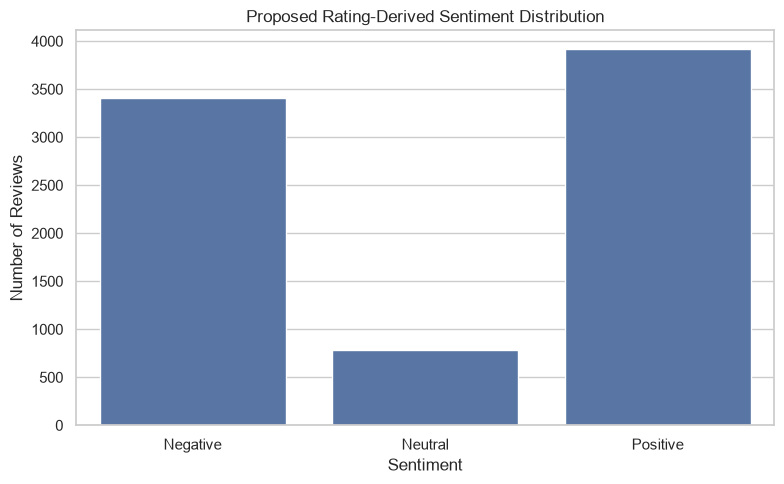

In [15]:

# ==========================================
# 12. PROPOSED SENTIMENT DISTRIBUTION
# ==========================================

def rating_to_sentiment(rating):

    if rating <= 4:
        return "Negative"

    elif rating <= 6:
        return "Neutral"

    else:
        return "Positive"


proposed_sentiment = df["Overall Rating"].apply(
    rating_to_sentiment
)

sentiment_distribution = pd.DataFrame({
    "Count": proposed_sentiment.value_counts(),
    "Percentage": (
        proposed_sentiment.value_counts(normalize=True) * 100
    ).round(2)
})

display(sentiment_distribution)

plt.figure(figsize=(8, 5))

sns.countplot(
    x=proposed_sentiment,
    order=["Negative", "Neutral", "Positive"]
)

plt.title("Proposed Rating-Derived Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()


In [16]:

# ==========================================
# 13. RECOMMENDATION TARGET VALIDATION
# ==========================================

recommendation = (
    df["Recommended"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("Recommendation values:")

display(recommendation.value_counts(dropna=False))

print("\nRecommendation percentages:")

display(
    (recommendation.value_counts(normalize=True) * 100).round(2)
)

print("\nUnexpected recommendation values:")

display(
    recommendation[~recommendation.isin(["yes", "no"])].value_counts()
)


Recommendation values:


Recommended
yes    4287
no     3813
Name: count, dtype: Int64


Recommendation percentages:


Recommended
yes    52.93
no     47.07
Name: proportion, dtype: Float64


Unexpected recommendation values:


Series([], Name: count, dtype: Int64)

,Review Count,Percentage
Airline,,
Turkish Airlines,1685,20.80
Qatar Airways,1624,20.05
Emirates,1350,16.67
Singapore Airlines,972,12.00
Air France,798,9.85
Cathay Pacific Airways,744,9.19
EVA Air,281,3.47
All Nippon Airways,258,3.19
Japan Airlines,201,2.48


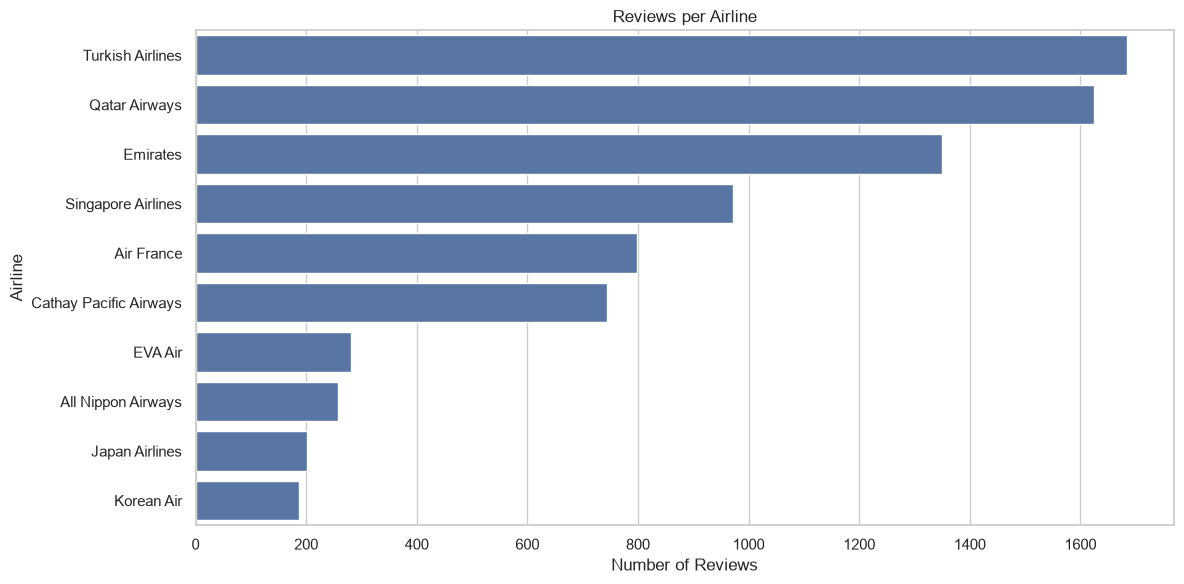

In [17]:

# ==========================================
# 14. AIRLINE DISTRIBUTION
# ==========================================

airline_distribution = pd.DataFrame({
    "Review Count": df["Airline"].value_counts(),
    "Percentage": (
        df["Airline"].value_counts(normalize=True) * 100
    ).round(2)
})

display(airline_distribution)

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Airline",
    order=df["Airline"].value_counts().index
)

plt.title("Reviews per Airline")
plt.xlabel("Number of Reviews")
plt.ylabel("Airline")

plt.tight_layout()
plt.show()


Sentiment,Negative,Neutral,Positive
Airline,,,
Air France,55.39,6.52,38.10
All Nippon Airways,13.57,6.98,79.46
Cathay Pacific Airways,33.33,11.16,55.51
EVA Air,18.15,9.61,72.24
Emirates,54.52,12.52,32.96
Japan Airlines,22.89,10.95,66.17
Korean Air,31.02,6.42,62.57
Qatar Airways,22.41,10.59,67.00
Singapore Airlines,28.81,12.35,58.85


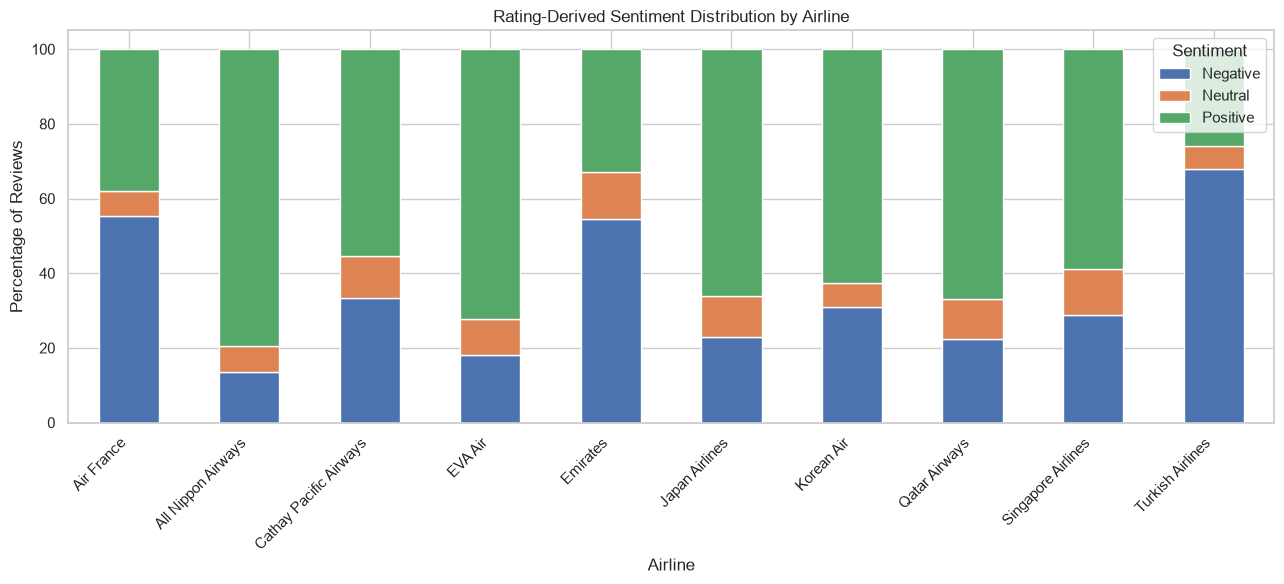

In [18]:

# ==========================================
# 15. SENTIMENT BY AIRLINE
# ==========================================

sentiment_analysis = pd.DataFrame({
    "Airline": df["Airline"],
    "Sentiment": proposed_sentiment
})

sentiment_pivot = pd.crosstab(
    sentiment_analysis["Airline"],
    sentiment_analysis["Sentiment"],
    normalize="index"
) * 100

display(sentiment_pivot.round(2))

sentiment_pivot[
    ["Negative", "Neutral", "Positive"]
].plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6)
)

plt.title("Rating-Derived Sentiment Distribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Percentage of Reviews")
plt.legend(title="Sentiment")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [20]:

# ==========================================
# 16. CREATE CLEANED WORKING DATASET
# ==========================================

df_raw= df.copy(deep=True)
df_clean = df_raw.copy(deep=True)

# Preserve the original verification field for auditing
df_clean["Verified_Raw"] = df_clean["Verified"].copy()

# Normalize whitespace in all original object columns
object_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns.tolist()

for col in object_columns:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

print("Whitespace normalization completed.")

print("Original dataset shape:", df_raw.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nRemaining missing values:")
display(
    df_clean.isna().sum().to_frame("Missing Values")
)


Whitespace normalization completed.
Original dataset shape: (8100, 17)
Cleaned dataset shape: (8100, 18)

Remaining missing values:


,Missing Values
Title,0
Name,0
Review Date,0
Airline,0
Verified,0
Reviews,0
Type of Traveller,0
Month Flown,0
Route,0
Class,0


In [21]:

# ==========================================
# 17. VERIFIED COLUMN STANDARDIZATION
# ==========================================

verified_mapping = {
    "true": True,
    "false": False
}

df_clean["Verified"] = (
    df_clean["Verified"]
    .astype("string")
    .str.lower()
    .map(verified_mapping)
    .astype("boolean")
)

print("Cleaned Verified distribution:")

display(
    df_clean["Verified"].value_counts(dropna=False)
)

print("\nUnknown verification entries:",
      df_clean["Verified"].isna().sum())

print("\nVerification data type:",
      df_clean["Verified"].dtype)


Cleaned Verified distribution:


Verified
True     6216
False    1881
<NA>        3
Name: count, dtype: Int64


Unknown verification entries: 3

Verification data type: boolean


In [22]:

# ==========================================
# 18. DATE CONVERSION
# ==========================================

df_clean["Review Date"] = pd.to_datetime(
    df_clean["Review Date"],
    format="%Y-%m-%d",
    errors="coerce"
)

df_clean["Month Flown"] = pd.to_datetime(
    df_clean["Month Flown"],
    format="%B %Y",
    errors="coerce"
)

date_audit = pd.DataFrame({
    "Column": ["Review Date", "Month Flown"],
    "Data Type": [
        str(df_clean["Review Date"].dtype),
        str(df_clean["Month Flown"].dtype)
    ],
    "Valid Values": [
        df_clean["Review Date"].notna().sum(),
        df_clean["Month Flown"].notna().sum()
    ],
    "Missing Values": [
        df_clean["Review Date"].isna().sum(),
        df_clean["Month Flown"].isna().sum()
    ]
})

display(date_audit)

print("\nReview date range:")
print(df_clean["Review Date"].min(),
      "to",
      df_clean["Review Date"].max())

print("\nFlight month range:")
print(df_clean["Month Flown"].min(),
      "to",
      df_clean["Month Flown"].max())


,Column,Data Type,Valid Values,Missing Values
0,Review Date,datetime64[ns],8100,0
1,Month Flown,datetime64[ns],8100,0



Review date range:
2016-03-22 00:00:00 to 2024-03-06 00:00:00

Flight month range:
2013-03-01 00:00:00 to 2024-03-01 00:00:00


In [23]:

# ==========================================
# 19. RECOMMENDATION LABEL PREPARATION
# ==========================================

df_clean["Recommended"] = (
    df_clean["Recommended"]
    .astype("string")
    .str.strip()
    .str.lower()
)

recommendation_mapping = {
    "no": 0,
    "yes": 1
}

df_clean["Recommended_Binary"] = (
    df_clean["Recommended"]
    .map(recommendation_mapping)
    .astype("int8")
)

print("Recommendation categories:")
display(df_clean["Recommended"].value_counts())

print("\nBinary target distribution:")
display(df_clean["Recommended_Binary"].value_counts().sort_index())

assert df_clean["Recommended_Binary"].notna().all()
assert set(df_clean["Recommended_Binary"].unique()) == {0, 1}


Recommendation categories:


Recommended
yes    4287
no     3813
Name: count, dtype: Int64


Binary target distribution:


Recommended_Binary
0    3813
1    4287
Name: count, dtype: int64

In [24]:

# ==========================================
# 20. SENTIMENT LABEL CREATION
# ==========================================

def rating_to_sentiment(rating: int) -> str:

    if rating <= 4:
        return "Negative"

    elif rating <= 6:
        return "Neutral"

    else:
        return "Positive"


df_clean["Sentiment_Label"] = (
    df_clean["Overall Rating"]
    .apply(rating_to_sentiment)
)

sentiment_mapping = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

df_clean["Sentiment_Code"] = (
    df_clean["Sentiment_Label"]
    .map(sentiment_mapping)
    .astype("int8")
)

print("Sentiment distribution:")

display(
    pd.DataFrame({
        "Count": df_clean["Sentiment_Label"].value_counts(),
        "Percentage": (
            df_clean["Sentiment_Label"]
            .value_counts(normalize=True) * 100
        ).round(2)
    })
)

print("\nSentiment codes:")
print(sentiment_mapping)


Sentiment distribution:


,Count,Percentage
Sentiment_Label,,
Positive,3915,48.33
Negative,3403,42.01
Neutral,782,9.65



Sentiment codes:
{'Negative': 0, 'Neutral': 1, 'Positive': 2}


In [25]:

# ==========================================
# 21. ENTERTAINMENT RATING ANOMALY FLAG
# ==========================================

df_clean["Entertainment_Rating_Zero"] = (
    df_clean["Inflight Entertainment"] == 0
)

print("Zero entertainment ratings:",
      df_clean["Entertainment_Rating_Zero"].sum())

print("\nRating distribution including zero:")

display(
    df_clean["Inflight Entertainment"].value_counts().sort_index()
)

print("\nAffected review:")

display(
    df_clean.loc[
        df_clean["Entertainment_Rating_Zero"],
        [
            "Airline",
            "Title",
            "Inflight Entertainment",
            "Overall Rating",
            "Recommended"
        ]
    ]
)


Zero entertainment ratings: 1

Rating distribution including zero:


Inflight Entertainment
0       1
1     863
2     741
3    1539
4    2284
5    2672
Name: count, dtype: int64


Affected review:


,Airline,Title,Inflight Entertainment,Overall Rating,Recommended
6757,Air France,no one is capable of giving you an answer,0,1,no


In [26]:

# ==========================================
# 22. REVIEW TEXT PREPARATION
# ==========================================

# Keep the normalized original review in its own column
df_clean["Review_Text_Clean"] = (
    df_clean["Reviews"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Create a comparison key for duplicate detection.
# This does not replace the actual review text.
df_clean["Review_Text_Key"] = (
    df_clean["Review_Text_Clean"]
    .str.casefold()
)

# Check empty reviews
empty_review_count = (
    df_clean["Review_Text_Clean"].isna() |
    df_clean["Review_Text_Clean"].str.strip().eq("")
).sum()

print("Empty reviews:", empty_review_count)

print("\nOriginal review sample:")
print(df_clean["Reviews"].iloc[0][:250])

print("\nCleaned review sample:")
print(df_clean["Review_Text_Clean"].iloc[0][:250])

assert empty_review_count == 0


Empty reviews: 0

Original review sample:
Flight was amazing. The crew onboard this flight were very welcoming, and gave a good atmosphere. The crew serving my aisle goes by the initial “G”. She was very kind & helpful. Gave my mom a bday cake for a late celebration even though it was just a

Cleaned review sample:
Flight was amazing. The crew onboard this flight were very welcoming, and gave a good atmosphere. The crew serving my aisle goes by the initial “G”. She was very kind & helpful. Gave my mom a bday cake for a late celebration even though it was just a


In [27]:

# ==========================================
# 23. REVIEW GROUP IDENTIFICATION
# ==========================================

# Assign the same group ID to identical normalized review texts
group_codes, unique_texts = pd.factorize(
    df_clean["Review_Text_Key"],
    sort=False
)

df_clean["Review_Group_ID"] = [
    f"REV_{code + 1:05d}"
    for code in group_codes
]

# Examine how many rows belong to each review group
group_sizes = (
    df_clean.groupby("Review_Group_ID")
    .size()
)

print("Total source records:", len(df_clean))
print("Unique review groups:", group_sizes.size)
print("Repeated review groups:", (group_sizes > 1).sum())
print("Extra duplicate rows:", len(df_clean) - group_sizes.size)

# Check consistency of sentiment and recommendation labels
group_label_consistency = (
    df_clean.groupby("Review_Group_ID")
    .agg(
        Unique_Sentiment=("Sentiment_Label", "nunique"),
        Unique_Recommendation=("Recommended_Binary", "nunique")
    )
)

inconsistent_groups = group_label_consistency[
    (group_label_consistency["Unique_Sentiment"] > 1) |
    (group_label_consistency["Unique_Recommendation"] > 1)
]

print("\nGroups with conflicting text-classification labels:",
      len(inconsistent_groups))

display(inconsistent_groups)

assert len(inconsistent_groups) == 0, (
    "Some identical review texts have conflicting labels. "
    "Investigate these before text-model training."
)


Total source records: 8100
Unique review groups: 8098
Repeated review groups: 2
Extra duplicate rows: 2

Groups with conflicting text-classification labels: 0


,Unique_Sentiment,Unique_Recommendation
Review_Group_ID,,


In [28]:

# ==========================================
# 24. DUPLICATED REVIEW GROUP INVESTIGATION
# ==========================================

repeated_group_ids = group_sizes[group_sizes > 1].index

duplicate_details = df_clean[
    df_clean["Review_Group_ID"].isin(repeated_group_ids)
].copy()

duplicate_display_columns = [
    "Review_Group_ID",
    "Title",
    "Airline",
    "Overall Rating",
    "Recommended",
    "Staff Service",
    "Seat Comfort",
    "Food & Beverages",
    "Reviews"
]

display(
    duplicate_details[duplicate_display_columns]
)

print("\nStructured rating comparison by repeated review group:")

rating_comparison = (
    duplicate_details
    .groupby("Review_Group_ID")[RATING_COLUMNS]
    .agg(["min", "max", "mean"])
)

display(rating_comparison)


,Review_Group_ID,Title,Airline,Overall Rating,Recommended,Staff Service,Seat Comfort,Food & Beverages,Reviews
3820,REV_03821,Hello Tomorrow? More like Hello Never,Emirates,2,no,5,3,5,"Unforgettable experience flying with Emirates from Singapore to Rome via Dubai. I was booked on flight EK433, with s..."
3821,REV_03821,More like Hello Never,Emirates,2,no,2,5,5,"Unforgettable experience flying with Emirates from Singapore to Rome via Dubai. I was booked on flight EK433, with s..."
7633,REV_07633,“an exceptional high level of service”,EVA Air,10,yes,5,5,5,Another great set of flights R/T Bangkok to San Francisco via Taipei. The EVA service from start to finish was 5 Sta...
7641,REV_07633,service from start to finish was 5 Star,EVA Air,10,yes,5,1,1,Another great set of flights R/T Bangkok to San Francisco via Taipei. The EVA service from start to finish was 5 Sta...



Structured rating comparison by repeated review group:


Seat Comfort          Staff Service          Food & Beverages  \
                         min max mean           min max mean              min   
Review_Group_ID                                                                 
REV_03821                  3   5  4.0             2   5  3.5                5   
REV_07633                  1   5  3.0             5   5  5.0                1   

                         Inflight Entertainment          Value For Money      \
                max mean                    min max mean             min max   
Review_Group_ID                                                                
REV_03821         5  5.0                      5   5  5.0               2   2   
REV_07633         5  3.0                      4   5  4.5               5   5   

                      
                mean  
Review_Group_ID       
REV_03821        2.0  
REV_07633        5.0

In [29]:

# ==========================================
# 25. UNIQUE REVIEW DATASET
# ==========================================

df_text_unique = (
    df_clean
    .drop_duplicates(
        subset=["Review_Text_Key"],
        keep="first"
    )
    .copy()
    .reset_index(drop=True)
)

print("Original source records:", len(df_clean))
print("Unique textual reviews:", len(df_text_unique))
print("Removed repeated text instances:",
      len(df_clean) - len(df_text_unique))

print("\nUnique review dataset shape:")
print(df_text_unique.shape)

print("\nSentiment distribution in unique reviews:")

display(
    df_text_unique["Sentiment_Label"]
    .value_counts()
)

print("\nRecommendation distribution in unique reviews:")

display(
    df_text_unique["Recommended"]
    .value_counts()
)

assert df_text_unique["Review_Text_Key"].is_unique


Original source records: 8100
Unique textual reviews: 8098
Removed repeated text instances: 2

Unique review dataset shape:
(8098, 25)

Sentiment distribution in unique reviews:


Sentiment_Label
Positive    3914
Negative    3402
Neutral      782
Name: count, dtype: int64


Recommendation distribution in unique reviews:


Recommended
yes    4286
no     3812
Name: count, dtype: Int64

In [30]:

# ==========================================
# 26. FINAL CLEANED DATASET VALIDATION
# ==========================================

validation_summary = pd.DataFrame({
    "Dataset": [
        "Original",
        "Cleaned source records",
        "Unique review records"
    ],
    "Rows": [
        len(df_raw),
        len(df_clean),
        len(df_text_unique)
    ],
    "Columns": [
        len(df_raw.columns),
        len(df_clean.columns),
        len(df_text_unique.columns)
    ]
})

display(validation_summary)

print("\nMissing values in cleaned source dataset:")

display(
    df_clean.isna().sum()[df_clean.isna().sum() > 0]
)

print("\nMissing values in unique review dataset:")

display(
    df_text_unique.isna().sum()[
        df_text_unique.isna().sum() > 0
    ]
)

print("\nFinal sentiment labels:")
print(df_text_unique["Sentiment_Label"].value_counts())

print("\nFinal recommendation labels:")
print(df_text_unique["Recommended"].value_counts())


,Dataset,Rows,Columns
0,Original,8100,17
1,Cleaned source records,8100,25
2,Unique review records,8098,25



Missing values in cleaned source dataset:


Verified    3
dtype: int64


Missing values in unique review dataset:


Verified    3
dtype: int64


Final sentiment labels:
Sentiment_Label
Positive    3914
Negative    3402
Neutral      782
Name: count, dtype: int64

Final recommendation labels:
Recommended
yes    4286
no     3812
Name: count, dtype: Int64


In [31]:

# ==========================================
# 27. SAVE CLEANED DATASETS
# ==========================================

PROCESSED_DIR = DATASET_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

CLEANED_DATA_PATH = (
    PROCESSED_DIR / "airline_reviews_cleaned.csv"
)

UNIQUE_DATA_PATH = (
    PROCESSED_DIR / "airline_reviews_unique.csv"
)

# Save both datasets
df_clean.to_csv(
    CLEANED_DATA_PATH,
    index=False
)

df_text_unique.to_csv(
    UNIQUE_DATA_PATH,
    index=False
)

print("Cleaned datasets saved successfully.")

print("Full cleaned dataset:")
print(CLEANED_DATA_PATH)

print("\nUnique review dataset:")
print(UNIQUE_DATA_PATH)


Cleaned datasets saved successfully.
Full cleaned dataset:
c:\Users\HP\Documents\Projects\FlightAura\dataset\processed\airline_reviews_cleaned.csv

Unique review dataset:
c:\Users\HP\Documents\Projects\FlightAura\dataset\processed\airline_reviews_unique.csv


## Stage 3 — Exploratory Data Analysis (EDA)

In [32]:

# ==========================================
# 28. OVERALL EDA SUMMARY
# ==========================================

print("=" * 65)
print("FLIGHTAURA — EXPLORATORY DATA ANALYSIS")
print("=" * 65)

print("\nTotal source records:", len(df_clean))
print("Unique textual reviews:", len(df_text_unique))
print("Airlines:", df_clean["Airline"].nunique())

print("\nReview date range:")
print(df_clean["Review Date"].min(),
      "to",
      df_clean["Review Date"].max())

print("\nFlight month range:")
print(df_clean["Month Flown"].min(),
      "to",
      df_clean["Month Flown"].max())

print("\nAverage overall rating:",
      round(df_clean["Overall Rating"].mean(), 2))

print("\nRecommendation rate:")
print(
    round(
        (df_clean["Recommended_Binary"].mean() * 100),
        2
    ),
    "%"
)

print("\nSentiment distribution:")
display(
    df_text_unique["Sentiment_Label"]
    .value_counts()
)


FLIGHTAURA — EXPLORATORY DATA ANALYSIS

Total source records: 8100
Unique textual reviews: 8098
Airlines: 10

Review date range:
2016-03-22 00:00:00 to 2024-03-06 00:00:00

Flight month range:
2013-03-01 00:00:00 to 2024-03-01 00:00:00

Average overall rating: 5.63

Recommendation rate:
52.93 %

Sentiment distribution:


Sentiment_Label
Positive    3914
Negative    3402
Neutral      782
Name: count, dtype: int64

,Review Count
Airline,
Turkish Airlines,1685
Qatar Airways,1624
Emirates,1350
Singapore Airlines,972
Air France,798
Cathay Pacific Airways,744
EVA Air,281
All Nippon Airways,258
Japan Airlines,201


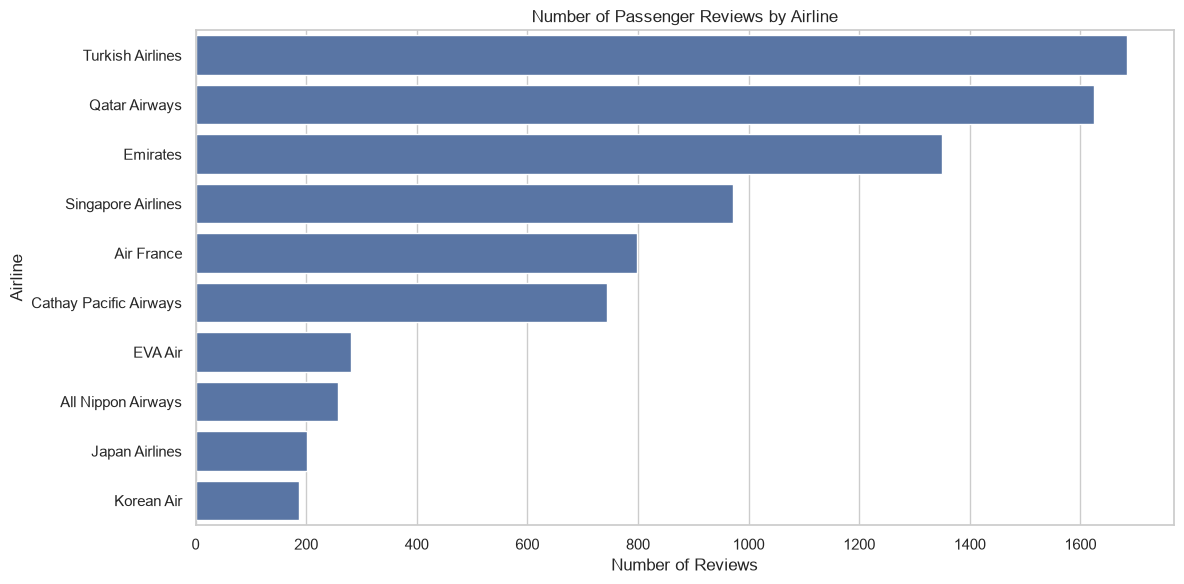

In [33]:

# ==========================================
# 29. AIRLINE REVIEW DISTRIBUTION
# ==========================================

airline_counts = (
    df_clean["Airline"]
    .value_counts()
    .sort_values(ascending=False)
)

display(
    airline_counts.to_frame("Review Count")
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=airline_counts.values,
    y=airline_counts.index
)

plt.title("Number of Passenger Reviews by Airline")
plt.xlabel("Number of Reviews")
plt.ylabel("Airline")

plt.tight_layout()
plt.show()


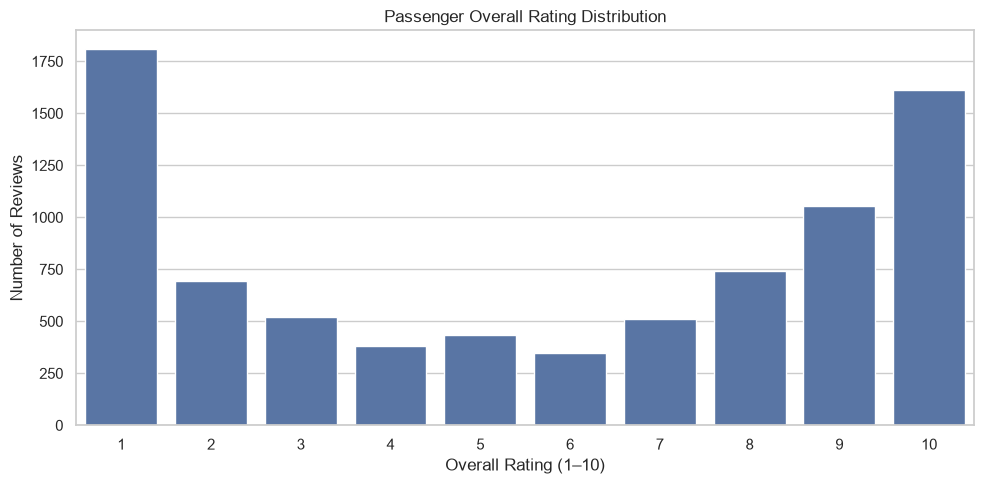

Rating percentages:


,Percentage
Overall Rating,
1,22.32
2,8.54
3,6.44
4,4.70
5,5.38
6,4.27
7,6.28
8,9.16
9,13.01


In [34]:

# ==========================================
# 30. OVERALL RATING DISTRIBUTION
# ==========================================

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="Overall Rating",
    order=sorted(df_clean["Overall Rating"].unique())
)

plt.title("Passenger Overall Rating Distribution")
plt.xlabel("Overall Rating (1–10)")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

print("Rating percentages:")

display(
    (
        df_clean["Overall Rating"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2).to_frame("Percentage")
)


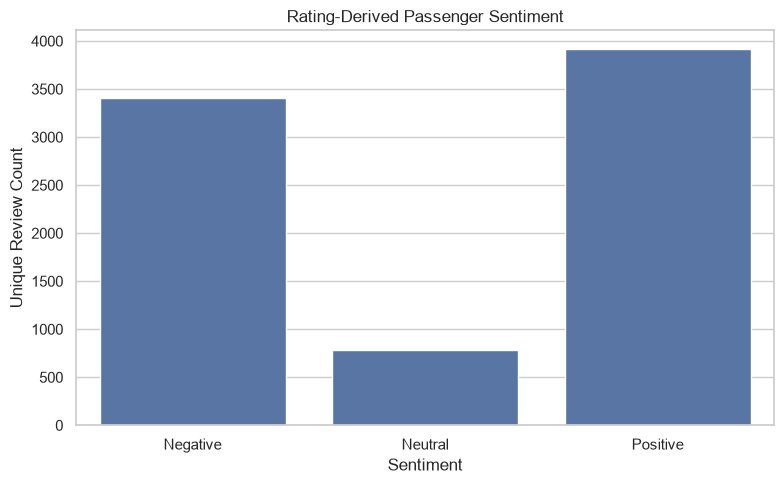

,Sentiment,Unique Review Count
0,Negative,3402
1,Neutral,782
2,Positive,3914


In [35]:
# ==========================================
# 31. SENTIMENT DISTRIBUTION
# ==========================================
sentiment_order = ["Negative", "Neutral", "Positive"]

sentiment_counts = (
    df_text_unique["Sentiment_Label"].value_counts().reindex(sentiment_order)
)

plt.figure(figsize=(8, 5))

sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values)

plt.title("Rating-Derived Passenger Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Unique Review Count")

plt.tight_layout()
plt.show()

# Displaying the counts as a structured summary table
display(
    pd.DataFrame(
        {
            "Sentiment": sentiment_counts.index,
            "Unique Review Count": sentiment_counts.values,
        }
    )
)
